# Capítulo 4: Relaciones No Lineales, Asimetría de Pérdidas y Cisnes Negros
> *Más allá de la línea recta: Por qué la física, los márgenes de seguridad y las consecuencias mandan sobre las métricas estadísticas.*

Este notebook contiene el código reproducible, las simulaciones financieras y los experimentos del **Capítulo 4**.

### Objetivos del Notebook:
1. **Modelar fenómenos no lineales acotados:** El caso agroindustrial del rendimiento en manteca de cacao en función de la humedad ($h$).
2. **Benchmark de arquitecturas de ML:** Comparar un modelo cuadrático baseline ($d=2$), Random Forest, XGBoost y Red Neuronal MLP.
3. **Construir zonas de precaución (Buffers de seguridad $z \cdot \sigma$):** Incorporar la asimetría de costos del negocio donde las multas por déficit (\$15.00/kg) son desproporcionadas frente al precio de venta (\$5.00/kg).
4. **Evaluar el impacto de Cisnes Negros (5% de catástrofes con $p=0$):** Entender por qué reentrenar a ciegas con outliers infla la varianza residual y paraliza comercialmente el negocio.
5. **Auditoría de residuos y MLOps:** Filtrar choques exógenos mediante un modelo auditor polinomial con umbral residual a $-20\%$.
6. **Optimizar el umbral de rechazo temprano en báscula ($th^*$):** Analizar el trade-off entre pérdidas evitadas y costo de oportunidad por falsos rechazos.

In [1]:
import os
import sys
import io
import json
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Reproducibilidad global
np.random.seed(2026)

# Estilo visual de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

## 1. El Proceso Físico y la Fisiología del Cacao

A diferencia de un escenario lineal simple, en la producción agrícola existen puntos óptimos y rendimientos decrecientes. Para el cacao (*Theobroma cacao*), el contenido de humedad ($h$) en el momento de recepción es la variable crítica:
* **Humedad deficiente ($h < 6.0\%$):** Almendras quebradizas, testa fracturada y merma severa de manteca de cacao.
* **Humedad óptima ($h \approx 7.2\%$):** Máxima recuperación de manteca fina de exportación ($P_{\text{MAX}} \approx 90\%$).
* **Humedad excesiva ($h > 8.5\%$):** Moho interno, acidificación y proliferación de hongos que arruinan la calidad para chocolatería fina.

El rendimiento de alta calidad $p(h)$ se modela como una función cuadrática estocástica acotada al dominio físico $[0, 100]\%$:
$$p(h) = \max\left(0, \min\left(100, P_{\text{MAX}} - K(h - H_{\text{OPT}})^2 + \epsilon\right)\right)$$
donde $\epsilon \sim \mathcal{N}(0, \sigma^2)$ representa el ruido natural por heterogeneidad de cosechas.

In [2]:
def simular_proceso_rendimiento(
    n_lotes=1000,
    h_opt=7.2,
    p_max=90.0,
    k=12.0,
    sigma_ruido=3.5,
    random_state=2026,
):
    """Simula la física del rendimiento de cacao según su humedad en báscula."""
    if random_state is not None:
        np.random.seed(random_state)

    # 70% de agricultores concentrados cerca del óptimo; 30% en colas de secado
    n_centro = int(n_lotes * 0.70)
    n_colas = n_lotes - n_centro
    h_centro = np.random.normal(loc=h_opt, scale=0.80, size=n_centro)
    h_colas = np.random.uniform(low=4.5, high=10.5, size=n_colas)

    humedad = np.clip(np.concatenate([h_centro, h_colas]), 3.0, 11.0)
    np.random.shuffle(humedad)

    p_teorico = p_max - k * ((humedad - h_opt) ** 2)
    ruido = np.random.normal(loc=0.0, scale=sigma_ruido, size=n_lotes)
    p_observado = np.clip(p_teorico + ruido, 0.0, 100.0)

    return pd.DataFrame({
        "humedad": np.round(humedad, 2),
        "p": np.round(p_observado, 2)
    })

df_base = simular_proceso_rendimiento(n_lotes=1000, random_state=2026)
print("Resumen estadístico de la muestra base (1,000 lotes):")
print(df_base.describe())

Resumen estadístico de la muestra base (1,000 lotes):
           humedad            p
count  1000.000000  1000.000000
mean      7.394520    73.771840
std       1.170923    23.641761
min       4.510000     0.000000
25%       6.690000    69.282500
50%       7.325000    83.375000
75%       8.082500    88.620000
max      10.500000    98.980000

### Sensibilidad Paramétrica Superpuesta
Para entender el impacto de los parámetros físicos ($P_{\text{MAX}}$, $H_{\text{OPT}}$, $K$ y $\sigma$), superponemos los valores contrastantes en un solo gráfico 2x2.

<string>:5: SyntaxWarning: invalid escape sequence '\s'

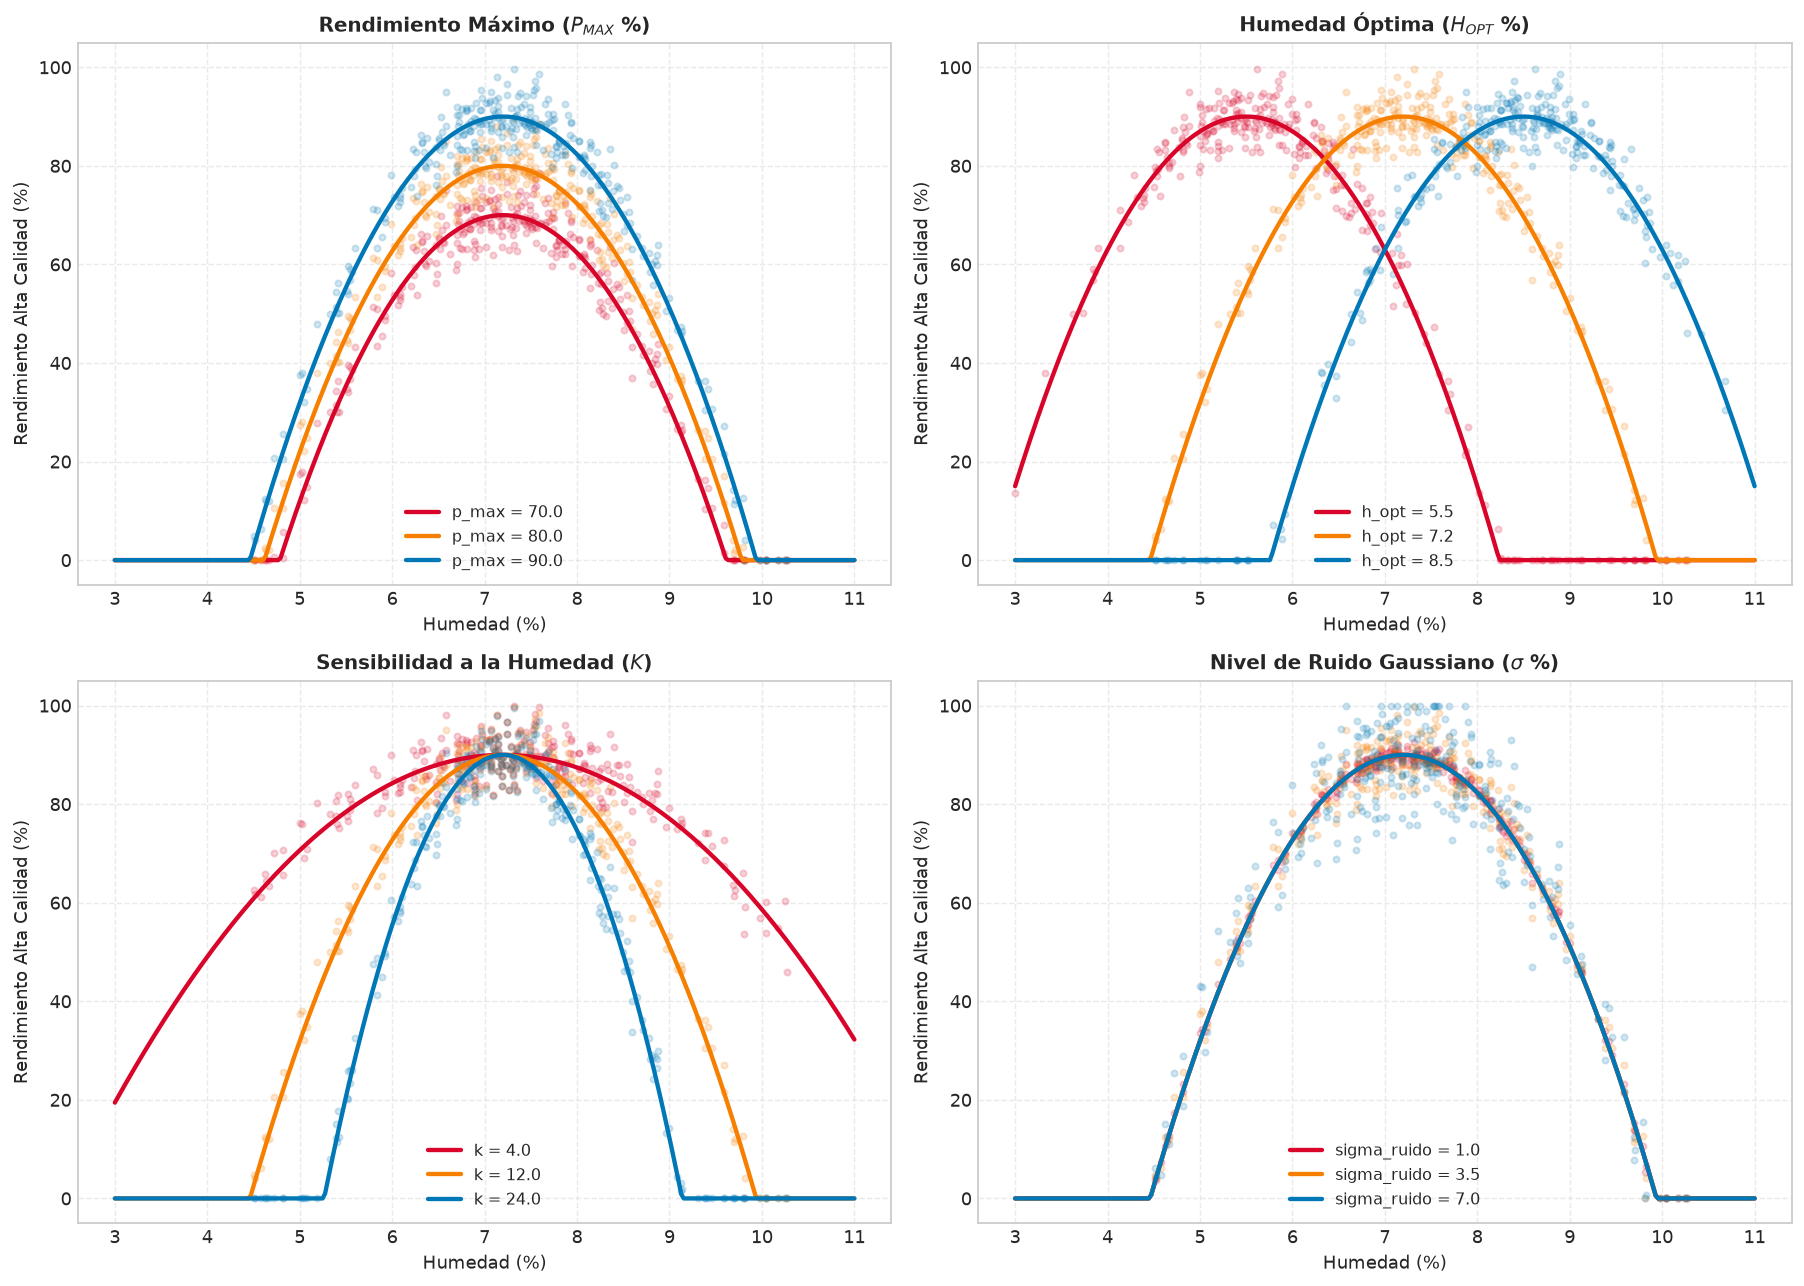

In [3]:
experimentos = {
    "p_max": ([70.0, 80.0, 90.0], "Rendimiento Máximo ($P_{MAX}$ %)"),
    "h_opt": ([5.5, 7.2, 8.5], "Humedad Óptima ($H_{OPT}$ %)"),
    "k": ([4.0, 12.0, 24.0], "Sensibilidad a la Humedad ($K$)"),
    "sigma_ruido": ([1.0, 3.5, 7.0], "Nivel de Ruido Gaussiano ($\sigma$ %)"),
}

colores = ["#d90429", "#f77f00", "#0077b6"]
h_linea = np.linspace(3.0, 11.0, 300)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (param, (valores, etiqueta)) in enumerate(experimentos.items()):
    ax = axes[idx]
    for val, color in zip(valores, colores):
        h_opt_val = val if param == "h_opt" else 7.2
        p_max_val = val if param == "p_max" else 90.0
        k_val = val if param == "k" else 12.0
        sigma_val = val if param == "sigma_ruido" else 3.5

        p_linea = np.clip(p_max_val - k_val * ((h_linea - h_opt_val) ** 2), 0.0, 100.0)
        df_sim = simular_proceso_rendimiento(**{param: val}, n_lotes=300, random_state=2026)

        ax.scatter(df_sim["humedad"], df_sim["p"], color=color, alpha=0.18, s=12)
        ax.plot(h_linea, p_linea, color=color, linewidth=2.4, label=f"{param} = {val}")

    ax.set_title(etiqueta, fontsize=11, fontweight="bold")
    ax.set_xlabel("Humedad (%)")
    ax.set_ylabel("Rendimiento Alta Calidad (%)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="lower center", fontsize=9)
    ax.set_ylim(-5, 105)

plt.tight_layout()
plt.show()

## 2. Ajuste de Modelos en Escenario Ideal (5 Años de Histórico)

Simulamos una operación continua de 5 años ($1,825$ lotes recibidos a razón de 1 lote/día). Separamos el 80% para entrenamiento y 20% para test.

Ajustamos 4 familias de modelos:
1. **Cuadrático Baseline:** `PolynomialFeatures(degree=2)` + `LinearRegression()`.
2. **Random Forest:** 150 árboles, profundidad máxima 6.
3. **XGBoost:** 150 estimadores, profundidad 3, tasa de aprendizaje 0.04.
4. **Perceptrón Multicapa (MLP):** Red neuronal $(64, 32)$ neuronas con ReLU tras estandarización.

In [4]:
df_hist = simular_proceso_rendimiento(n_lotes=365 * 5, random_state=2026)

X = df_hist[['humedad']]
y = df_hist['p']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

modelos = {
    'Cuadrático Baseline': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('linear', LinearRegression())
    ]),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=6, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.04, random_state=42),
    'MLP (Red Neuronal)': Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', max_iter=2500, random_state=42))
    ])
}

for nombre, mod in modelos.items():
    mod.fit(X_train, y_train)

print(f"Histórico total: {len(df_hist)} lotes (Train: {len(X_train)}, Test: {len(X_test)})")
print("Modelos entrenados con éxito.")

Histórico total: 1825 lotes (Train: 1460, Test: 365)
Modelos entrenados con éxito.

### Comparación Funcional en un Mismo Plano Continuo
Evaluamos las predicciones continuas sobre el rango $h \in [4.5\%, 10.0\%]$ comparándolas directamente con la curva teórica oculta (*Ground Truth*).

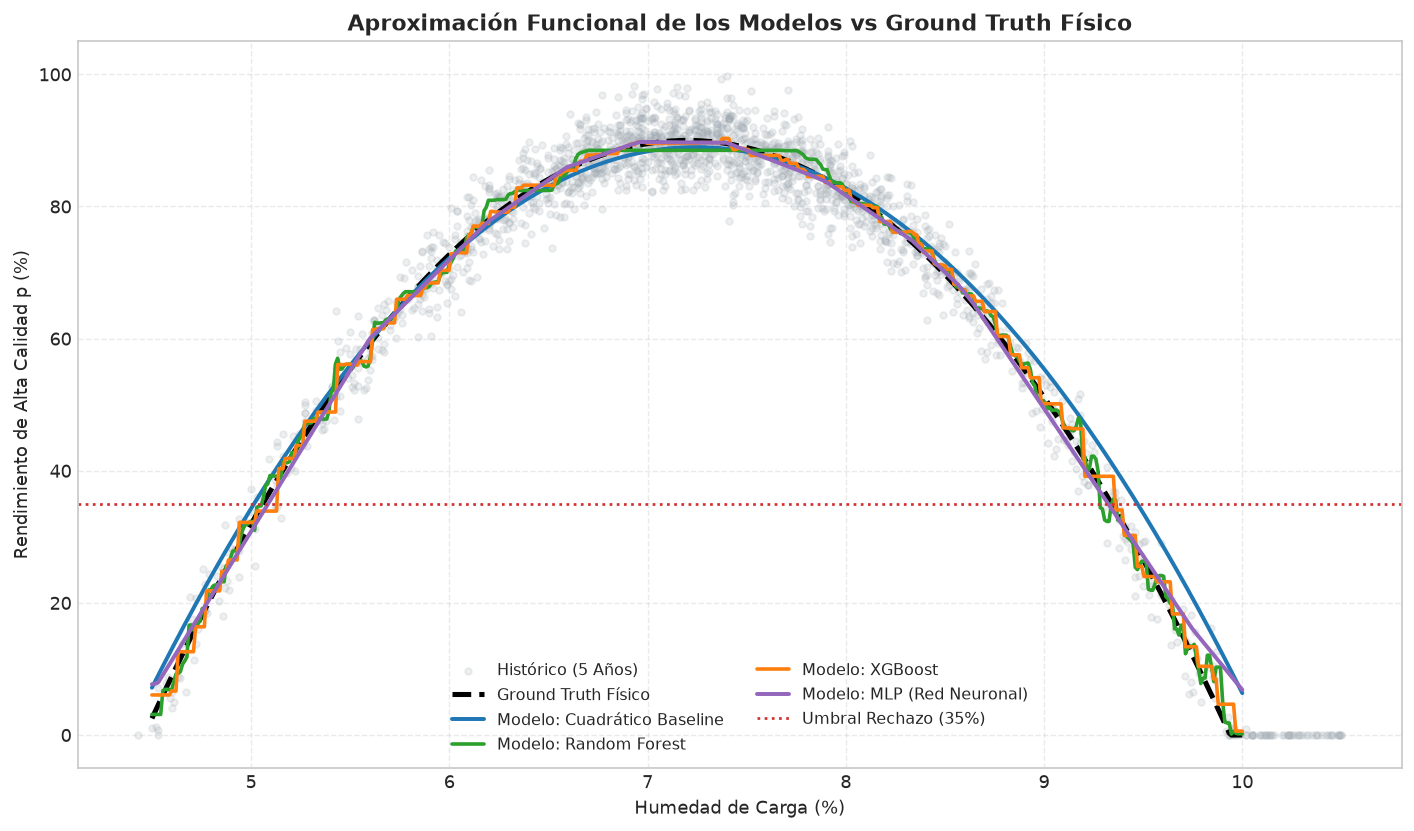

In [5]:
h_grid = np.linspace(4.5, 10.0, 500).reshape(-1, 1)
df_grid = pd.DataFrame(h_grid, columns=['humedad'])
p_ground_truth = np.clip(90.0 - 12.0 * ((h_grid.flatten() - 7.2) ** 2), 0.0, 100.0)

plt.figure(figsize=(11, 6.5))
plt.scatter(df_hist['humedad'], df_hist['p'], color='#a0aab2', alpha=0.18, s=14, label='Histórico (5 Años)')
plt.plot(h_grid, p_ground_truth, 'k--', linewidth=2.8, label='Ground Truth Físico')

estilos = {
    'Cuadrático Baseline': {'color': '#1f77b4', 'lw': 2.2},
    'Random Forest': {'color': '#2ca02c', 'lw': 2.0},
    'XGBoost': {'color': '#ff7f0e', 'lw': 2.0},
    'MLP (Red Neuronal)': {'color': '#9467bd', 'lw': 2.2},
}

for nombre, mod in modelos.items():
    preds = np.clip(mod.predict(df_grid), 0.0, 100.0)
    plt.plot(h_grid, preds, label=f'Modelo: {nombre}', color=estilos[nombre]['color'], linewidth=estilos[nombre]['lw'])

plt.axhline(35.0, color='#d32f2f', linestyle=':', linewidth=1.5, label='Umbral Rechazo (35%)')
plt.title('Aproximación Funcional de los Modelos vs Ground Truth Físico', fontsize=12, fontweight='bold')
plt.xlabel('Humedad de Carga (%)')
plt.ylabel('Rendimiento de Alta Calidad p (%)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='lower center', fontsize=9, ncol=2)
plt.ylim(-5, 105)
plt.tight_layout()
plt.show()

### Métricas de Rendimiento en Test Set
Calculamos el error cuadrático medio ($\text{RMSE}$), error absoluto medio ($\text{MAE}$), $R^2$ y la desviación estándar de los residuos de calibración ($\sigma_{\text{res}}$).

In [6]:
sigmas_residuales = {}
metricas = []

for nombre, mod in modelos.items():
    preds_train = mod.predict(X_train)
    residuos_train = y_train - preds_train
    sigma = np.std(residuos_train, ddof=1)
    sigmas_residuales[nombre] = sigma

    preds_test = mod.predict(X_test)
    mae = mean_absolute_error(y_test, preds_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds_test))
    r2 = r2_score(y_test, preds_test)

    # Cobertura empírica bilateral al 95% (z = 1.96)
    banda_inf = preds_test - (1.96 * sigma)
    banda_sup = preds_test + (1.96 * sigma)
    cobertura = np.mean((y_test >= banda_inf) & (y_test <= banda_sup)) * 100.0

    metricas.append({
        'Modelo': nombre,
        'RMSE (%)': round(rmse, 3),
        'MAE (%)': round(mae, 3),
        'R² Score': round(r2, 4),
        'σ Residual (%)': round(sigma, 3),
        'Buffer Unilateral (z=1.65)': f"{1.645 * sigma:.2f}%",
        'Cobertura Test (%)': f"{cobertura:.1f}%"
    })

df_metricas = pd.DataFrame(metricas).sort_values(by='RMSE (%)').reset_index(drop=True)
print("Tabla 1: Métricas de Rendimiento en Test y Calibración de Buffers:")
print(df_metricas.to_string(index=False))

Tabla 1: Métricas de Rendimiento en Test y Calibración de Buffers:
             Modelo  RMSE (%)  MAE (%)  R² Score  σ Residual (%) Buffer Unilateral (z=1.65) Cobertura Test (%)
            XGBoost     3.440    2.736    0.9715           3.282                      5.40%              92.1%
 MLP (Red Neuronal)     3.495    2.745    0.9705           3.662                      6.02%              95.9%
      Random Forest     3.501    2.760    0.9705           3.350                      5.51%              93.7%
Cuadrático Baseline     4.122    3.152    0.9590           4.708                      7.74%              95.9%

## 3. La Zona de Precaución: Construcción del Seguro Comercial ($z \cdot \sigma$)

En el negocio del cacao procesamos **lotes diarios de 1,000 kg**.
Las condiciones comerciales son fuertemente asimétricas:
* **Venta garantizada por contrato:** \$5.00/kg.
* **Mercado secundario (desvío spot):** \$1.20/kg.
* **Penalización por déficit en contrato:** **\$15.00/kg**.

Si el modelo predice $80\%$ de calidad pero el lote rinde $75\%$, el déficit de $50\text{ kg}$ genera una multa de $\$750$, triplicando el margen de venta.
Por eso, para compromisos comerciales aplicamos un **descuento prudencial (Buffer de Seguridad)**:
$$p_{\text{seguro}} = \max\left(0, \hat{p} - z \cdot \sigma_{\text{res}}\right), \quad z = 1.645 \implies \text{Nivel de servicio } 95\%$$

A continuación graficamos cada modelo con su **segunda curva inferior (nuestro seguro)**.

<string>:20: SyntaxWarning: invalid escape sequence '\s'

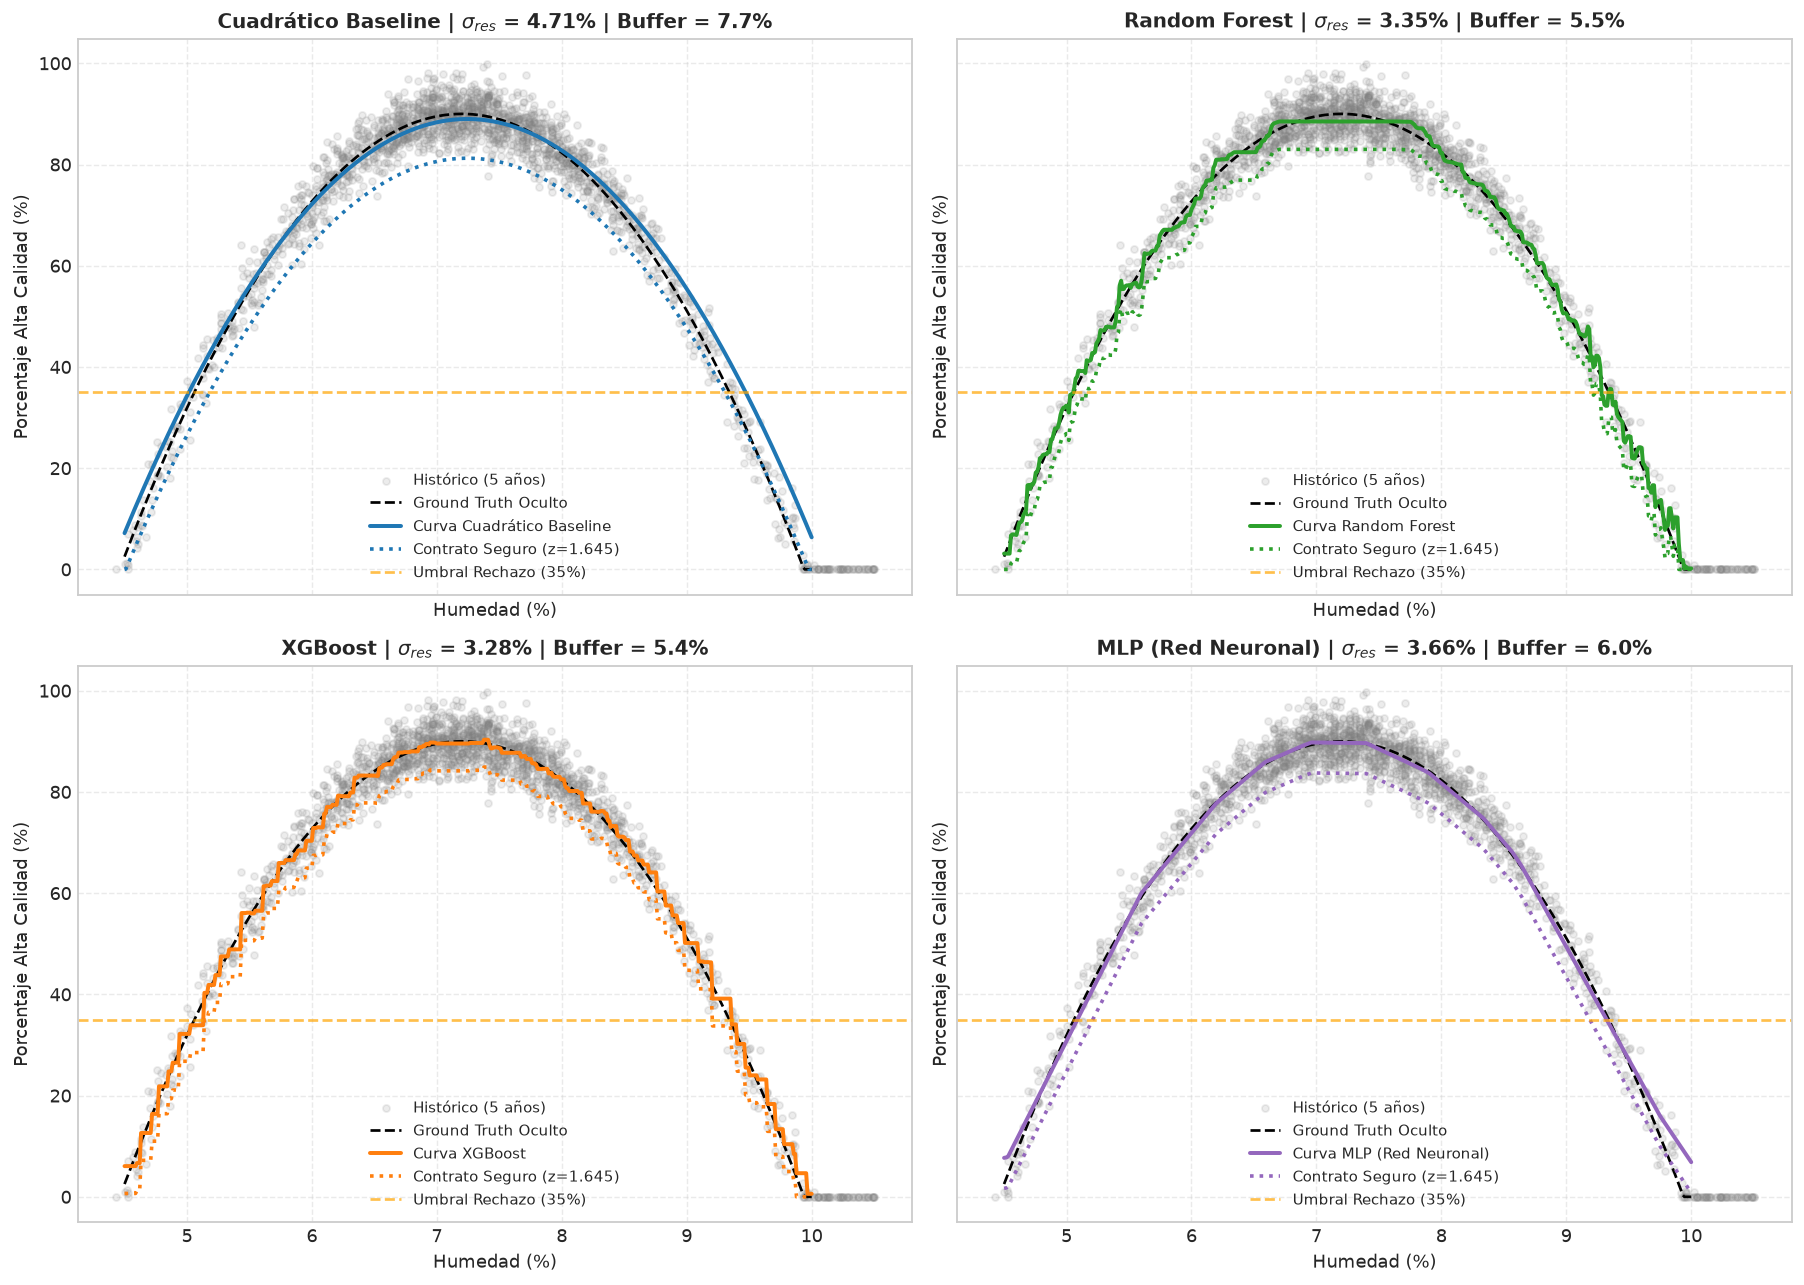

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()
colores = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd']
Z_VAL = 1.645

for idx, (nombre, mod) in enumerate(modelos.items()):
    ax = axes[idx]
    sigma = sigmas_residuales[nombre]
    buffer = Z_VAL * sigma

    pred_grid = np.clip(mod.predict(df_grid), 0.0, 100.0)
    pred_buffer = np.clip(pred_grid - buffer, 0.0, 100.0)

    ax.scatter(df_hist['humedad'], df_hist['p'], color='gray', alpha=0.15, s=15, label='Histórico (5 años)')
    ax.plot(h_grid, p_ground_truth, 'k--', linewidth=1.5, label='Ground Truth Oculto')
    ax.plot(h_grid, pred_grid, color=colores[idx], linewidth=2.2, label=f'Curva {nombre}')
    ax.plot(h_grid, pred_buffer, color=colores[idx], linestyle=':', linewidth=2.0, label=f'Contrato Seguro (z={Z_VAL})')
    ax.axhline(35, color='orange', linestyle='--', alpha=0.7, label='Umbral Rechazo (35%)')

    ax.set_title(f'{nombre} | $\sigma_{{res}}$ = {sigma:.2f}% | Buffer = {buffer:.1f}%', fontsize=11, fontweight='bold')
    ax.set_ylabel('Porcentaje Alta Calidad (%)')
    ax.set_xlabel('Humedad (%)')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower center', fontsize=8.5)

plt.tight_layout()
plt.show()

### Motor de Simulación Contractual
Evaluamos 2 años de producción futura fuera de muestra ($730$ lotes) bajo dos políticas:
1. **Estrategia Directa:** Prometer el 100% de la predicción media ($\hat{p}$).
2. **Estrategia Conservadora:** Prometer con el buffer de seguridad ($p_{\text{seguro}} = \hat{p} - 1.645 \cdot \sigma_{\text{res}}$).

In [8]:
def ejecutar_simulacion(
    df_test,
    modelo,
    buffer_val=0.0,
    col_y="p",
    peso_lote=1000,
    p_alta=5.00,
    p_baja=1.20,
    multa=15.00,
    costo_compra=2000.0,
    costo_proceso=300.0,
    umbral_rechazo=35.0,
):
    if col_y not in df_test.columns and "p_real" in df_test.columns:
        col_y = "p_real"

    preds_raw = np.clip(modelo.predict(df_test[["humedad"]]), 0.0, 100.0)

    ingreso_alta_tot, ingreso_baja_tot = 0.0, 0.0
    costo_compra_tot, costo_proceso_tot = 0.0, 0.0
    multas_tot, beneficio_tot = 0.0, 0.0
    kg_alta_tot, kg_baja_tot, kg_mult_tot = 0.0, 0.0, 0.0
    lotes_proc, lotes_mult = 0, 0
    curva_acumulada = []

    costo_base_lote = costo_compra + costo_proceso

    for real, pred in zip(df_test[col_y], preds_raw):
        if pred < umbral_rechazo:
            curva_acumulada.append(beneficio_tot)
            continue

        lotes_proc += 1
        costo_compra_tot += costo_compra
        costo_proceso_tot += costo_proceso

        kg_real_alta = (real / 100.0) * peso_lote
        kg_real_baja = ((100.0 - real) / 100.0) * peso_lote

        p_comp = max(0.0, pred - buffer_val)
        kg_comp_alta = (p_comp / 100.0) * peso_lote

        if kg_real_alta >= kg_comp_alta:
            kg_v_alta = kg_comp_alta
            kg_v_baja = kg_real_baja + (kg_real_alta - kg_comp_alta)
            m_lote = 0.0
        else:
            kg_v_alta = kg_real_alta
            kg_v_baja = kg_real_baja
            kg_mult_lote = kg_comp_alta - kg_real_alta
            m_lote = kg_mult_lote * multa
            multas_tot += m_lote
            kg_mult_tot += kg_mult_lote
            lotes_mult += 1

        kg_alta_tot += kg_v_alta
        kg_baja_tot += kg_v_baja

        ing_alta = kg_v_alta * p_alta
        ing_baja = kg_v_baja * p_baja
        ingreso_alta_tot += ing_alta
        ingreso_baja_tot += ing_baja

        beneficio_lote = (ing_alta + ing_baja) - (costo_base_lote + m_lote)
        beneficio_tot += beneficio_lote
        curva_acumulada.append(beneficio_tot)

    return {
        "Lotes Procesados": lotes_proc,
        "Lotes Multados": lotes_mult,
        "Tasa Falla (%)": round((lotes_mult / lotes_proc) * 100, 1) if lotes_proc > 0 else 0.0,
        "Kg Vendidos Alta": round(kg_alta_tot, 1),
        "Kg Vendidos Baja": round(kg_baja_tot, 1),
        "Kg Multados": round(kg_mult_tot, 1),
        "Ingresos ($k)": round((ingreso_alta_tot + ingreso_baja_tot) / 1000.0, 1),
        "Costos ($k)": round((costo_compra_tot + costo_proceso_tot + multas_tot) / 1000.0, 1),
        "Multas ($k)": round(multas_tot / 1000.0, 1),
        "Beneficio Neto ($k)": round(beneficio_tot / 1000.0, 1),
        "Curva_Acumulada": curva_acumulada,
    }

df_futuro_ideal = simular_proceso_rendimiento(n_lotes=365 * 2, random_state=42)
res_directo = {}
res_buffer = {}

for nombre, mod in modelos.items():
    sigma = sigmas_residuales[nombre]
    res_directo[nombre] = ejecutar_simulacion(df_futuro_ideal, mod, buffer_val=0.0, multa=15.0)
    res_buffer[nombre] = ejecutar_simulacion(df_futuro_ideal, mod, buffer_val=1.645 * sigma, multa=15.0)

df_comp_ideal = pd.DataFrame({
    "Beneficio Directo ($k)": [res_directo[m]["Beneficio Neto ($k)"] for m in modelos.keys()],
    "Beneficio Seguro ($k)": [res_buffer[m]["Beneficio Neto ($k)"] for m in modelos.keys()],
    "Delta Ganancia ($k)": [round(res_buffer[m]["Beneficio Neto ($k)"] - res_directo[m]["Beneficio Neto ($k)"], 1) for m in modelos.keys()],
    "Multas Directo ($k)": [res_directo[m]["Multas ($k)"] for m in modelos.keys()],
    "Multas Seguro ($k)": [res_buffer[m]["Multas ($k)"] for m in modelos.keys()],
    "Falla Directo (%)": [res_directo[m]["Tasa Falla (%)"] for m in modelos.keys()],
    "Falla Seguro (%)": [res_buffer[m]["Tasa Falla (%)"] for m in modelos.keys()],
}, index=list(modelos.keys()))

print("Comparativa Económica en Escenario Ideal (730 lotes / 2 años):")
print(df_comp_ideal.to_string())

Comparativa Económica en Escenario Ideal (730 lotes / 2 años):
                     Beneficio Directo ($k)  Beneficio Seguro ($k)  Delta Ganancia ($k)  Multas Directo ($k)  Multas Seguro ($k)  Falla Directo (%)  Falla Seguro (%)
Cuadrático Baseline             1110.300000                 1097.5                -12.8           153.000000                 4.7               49.5               3.3
Random Forest                   1108.800000                 1147.3                 38.5           155.200000                12.8               52.5               7.3
XGBoost                         1114.699951                 1149.7                 35.0           148.699997                11.7               51.1               6.0
MLP (Red Neuronal)              1128.100000                 1134.0                  5.9           133.800000                 7.0               47.8               3.7

### Trayectoria Temporal de Beneficio Acumulado (2 Años)
Comparamos las curvas acumuladas continuas entre operar a ciegas sin seguro vs con el seguro del 95%.

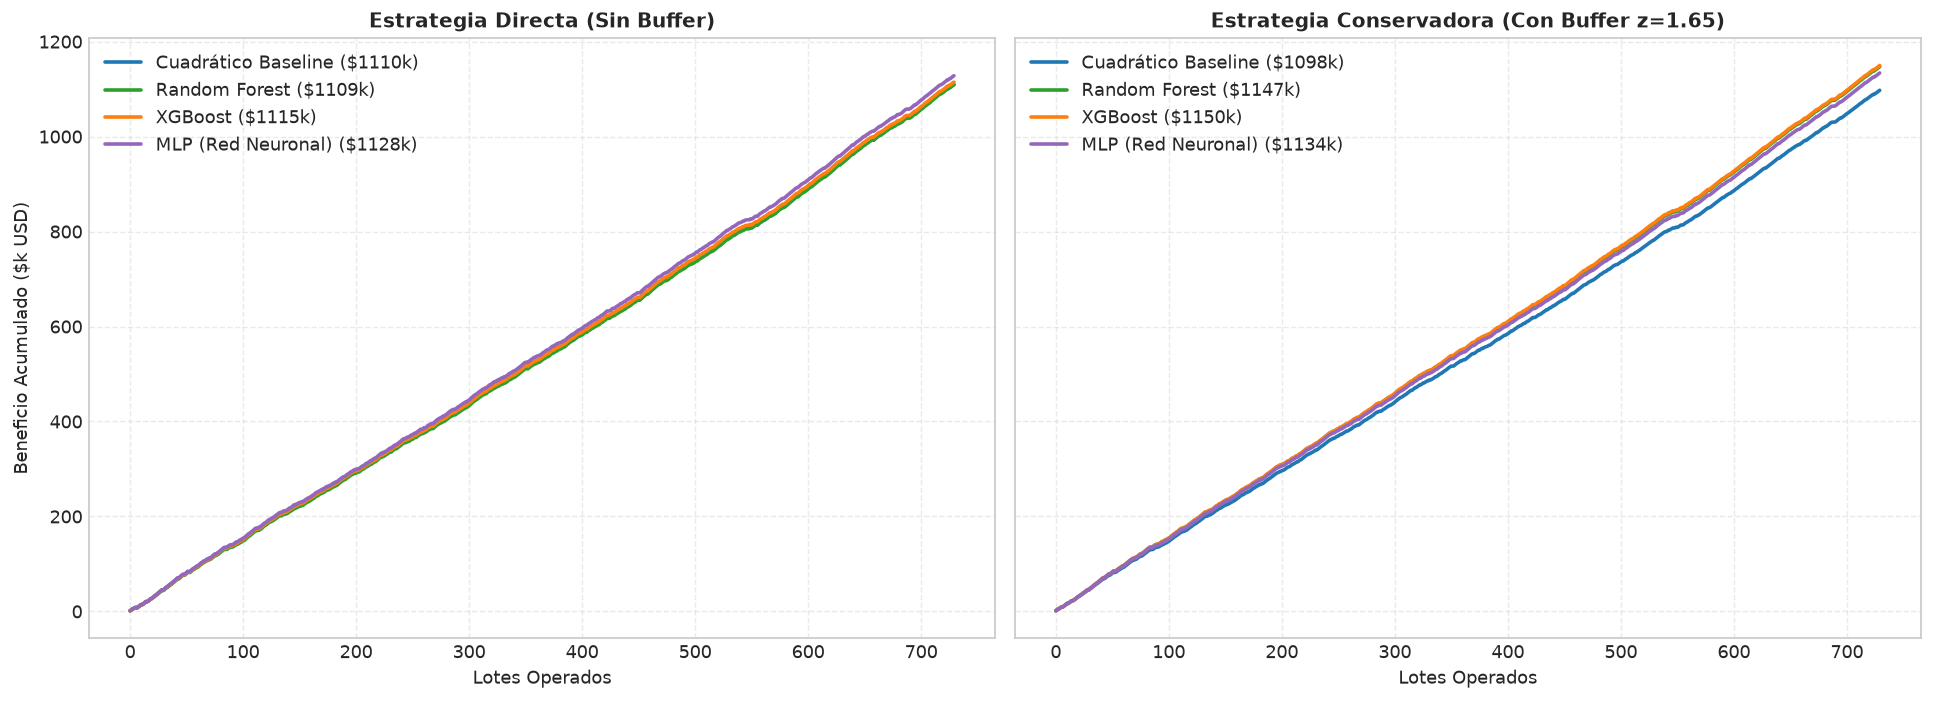

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
colores_mod = {
    "Cuadrático Baseline": "#1f77b4",
    "Random Forest": "#2ca02c",
    "XGBoost": "#ff7f0e",
    "MLP (Red Neuronal)": "#9467bd"
}

for nombre, res in res_directo.items():
    curva = np.array(res["Curva_Acumulada"]) / 1000.0
    ax1.plot(curva, label=f"{nombre} (${res['Beneficio Neto ($k)']:.0f}k)", color=colores_mod[nombre], lw=2.0)

for nombre, res in res_buffer.items():
    curva = np.array(res["Curva_Acumulada"]) / 1000.0
    ax2.plot(curva, label=f"{nombre} (${res['Beneficio Neto ($k)']:.0f}k)", color=colores_mod[nombre], lw=2.0)

ax1.set_title("Estrategia Directa (Sin Buffer)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Lotes Operados")
ax1.set_ylabel("Beneficio Acumulado ($k USD)")
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="upper left")

ax2.set_title("Estrategia Conservadora (Con Buffer z=1.65)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Lotes Operados")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 4. Inyección de Catástrofes (Cisnes Negros): La Ruina del Modelo Sucio

En la agricultura existen choques exógenos impredecibles independientes de la humedad:
* Infección fulminante por *Monilia roreri*.
* Inundaciones o fermentación acética en bodega.

Introducimos una tasa de catástrofe del **5%** ($p_{\text{real}} = 0.0\%$).
¿Qué ocurre si entrenamos a ciegas con todos los datos sucios?
1. El modelo intenta ajustar las catástrofes y su varianza residual explota: $\sigma_{\text{res}}$ pasa de $\sim 3.4\%$ a **$\sim 16.6\%$**.
2. Al multiplicar por $z=1.645$, el buffer se dilata hasta casi un **$28\%$**.
3. **Parálisis Comercial:** «Nuestros seguros se van al piso». Dejamos de vender decenas de toneladas a precio premium por un exceso destructivo de prudencia.

In [10]:
def generar_datos_cacao(anios_hist=5, anios_futuro=2, lotes_anio=260, prob_catastrofe=0.05, seed=42):
    np.random.seed(seed)
    total_lotes = (anios_hist + anios_futuro) * lotes_anio

    h_centro = np.random.normal(7.2, 0.65, int(total_lotes * 0.80))
    h_colas = np.random.uniform(5.0, 9.6, int(total_lotes * 0.20))
    humedad = np.clip(np.concatenate([h_centro, h_colas]), 5.0, 9.6)
    np.random.shuffle(humedad)

    p_teorico = 90.0 - 12.0 * ((humedad - 7.2) ** 2)
    ruido = np.random.normal(0, 3.5, total_lotes)
    p_real = np.clip(p_teorico + ruido, 0.0, 100.0)

    es_catastrofe = np.random.binomial(1, prob_catastrofe, total_lotes).astype(bool)
    p_real[es_catastrofe] = 0.0

    fechas = pd.date_range(start="2020-01-01", periods=total_lotes, freq="B")

    df = pd.DataFrame({
        'fecha': fechas,
        'anio': np.repeat(np.arange(1, anios_hist + anios_futuro + 1), lotes_anio),
        'humedad': np.round(humedad, 2),
        'p_real': np.round(p_real, 2),
        'es_catastrofe': es_catastrofe
    })
    return df, anios_hist

df_total, limite_hist = generar_datos_cacao(anios_hist=5, anios_futuro=2, prob_catastrofe=0.05)
df_hist_sucio = df_total[df_total['anio'] <= limite_hist].copy()
df_futuro_catastrofe = df_total[df_total['anio'] > limite_hist].copy()

def crear_suite_modelos():
    return {
        'Cuadrático Baseline': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('linear', LinearRegression())
        ]),
        'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=6, random_state=42),
        'XGBoost': XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.04, random_state=42),
        'MLP (Red Neuronal)': Pipeline([
            ('scaler', StandardScaler()),
            ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', max_iter=2500, random_state=42))
        ])
    }

modelos_sucios = crear_suite_modelos()
sigmas_sucios = {}

for nombre, mod in modelos_sucios.items():
    mod.fit(df_hist_sucio[['humedad']], df_hist_sucio['p_real'])
    preds_s = mod.predict(df_hist_sucio[['humedad']])
    sigmas_sucios[nombre] = np.std(df_hist_sucio['p_real'] - preds_s, ddof=1)

print("Explosión de Sigmas Residuales bajo datos sucios:")
for k, v in sigmas_sucios.items():
    print(f"  {k}: σ = {v:.2f}%  --> Buffer (z=1.65) = {1.645 * v:.2f}%")

Explosión de Sigmas Residuales bajo datos sucios:
  Cuadrático Baseline: σ = 17.18%  --> Buffer (z=1.65) = 28.27%
  Random Forest: σ = 16.18%  --> Buffer (z=1.65) = 26.62%
  XGBoost: σ = 16.56%  --> Buffer (z=1.65) = 27.24%
  MLP (Red Neuronal): σ = 17.21%  --> Buffer (z=1.65) = 28.32%

### Visualización: Curvas Sucias y Colapso del Seguro (Figura 3)
Observe cómo la línea punteada del seguro cae estrepitosamente hacia valores cercanos al 10% - 20%, bloqueando la venta garantizada.

<string>:18: SyntaxWarning: invalid escape sequence '\s'
<string>:21: SyntaxWarning: invalid escape sequence '\s'

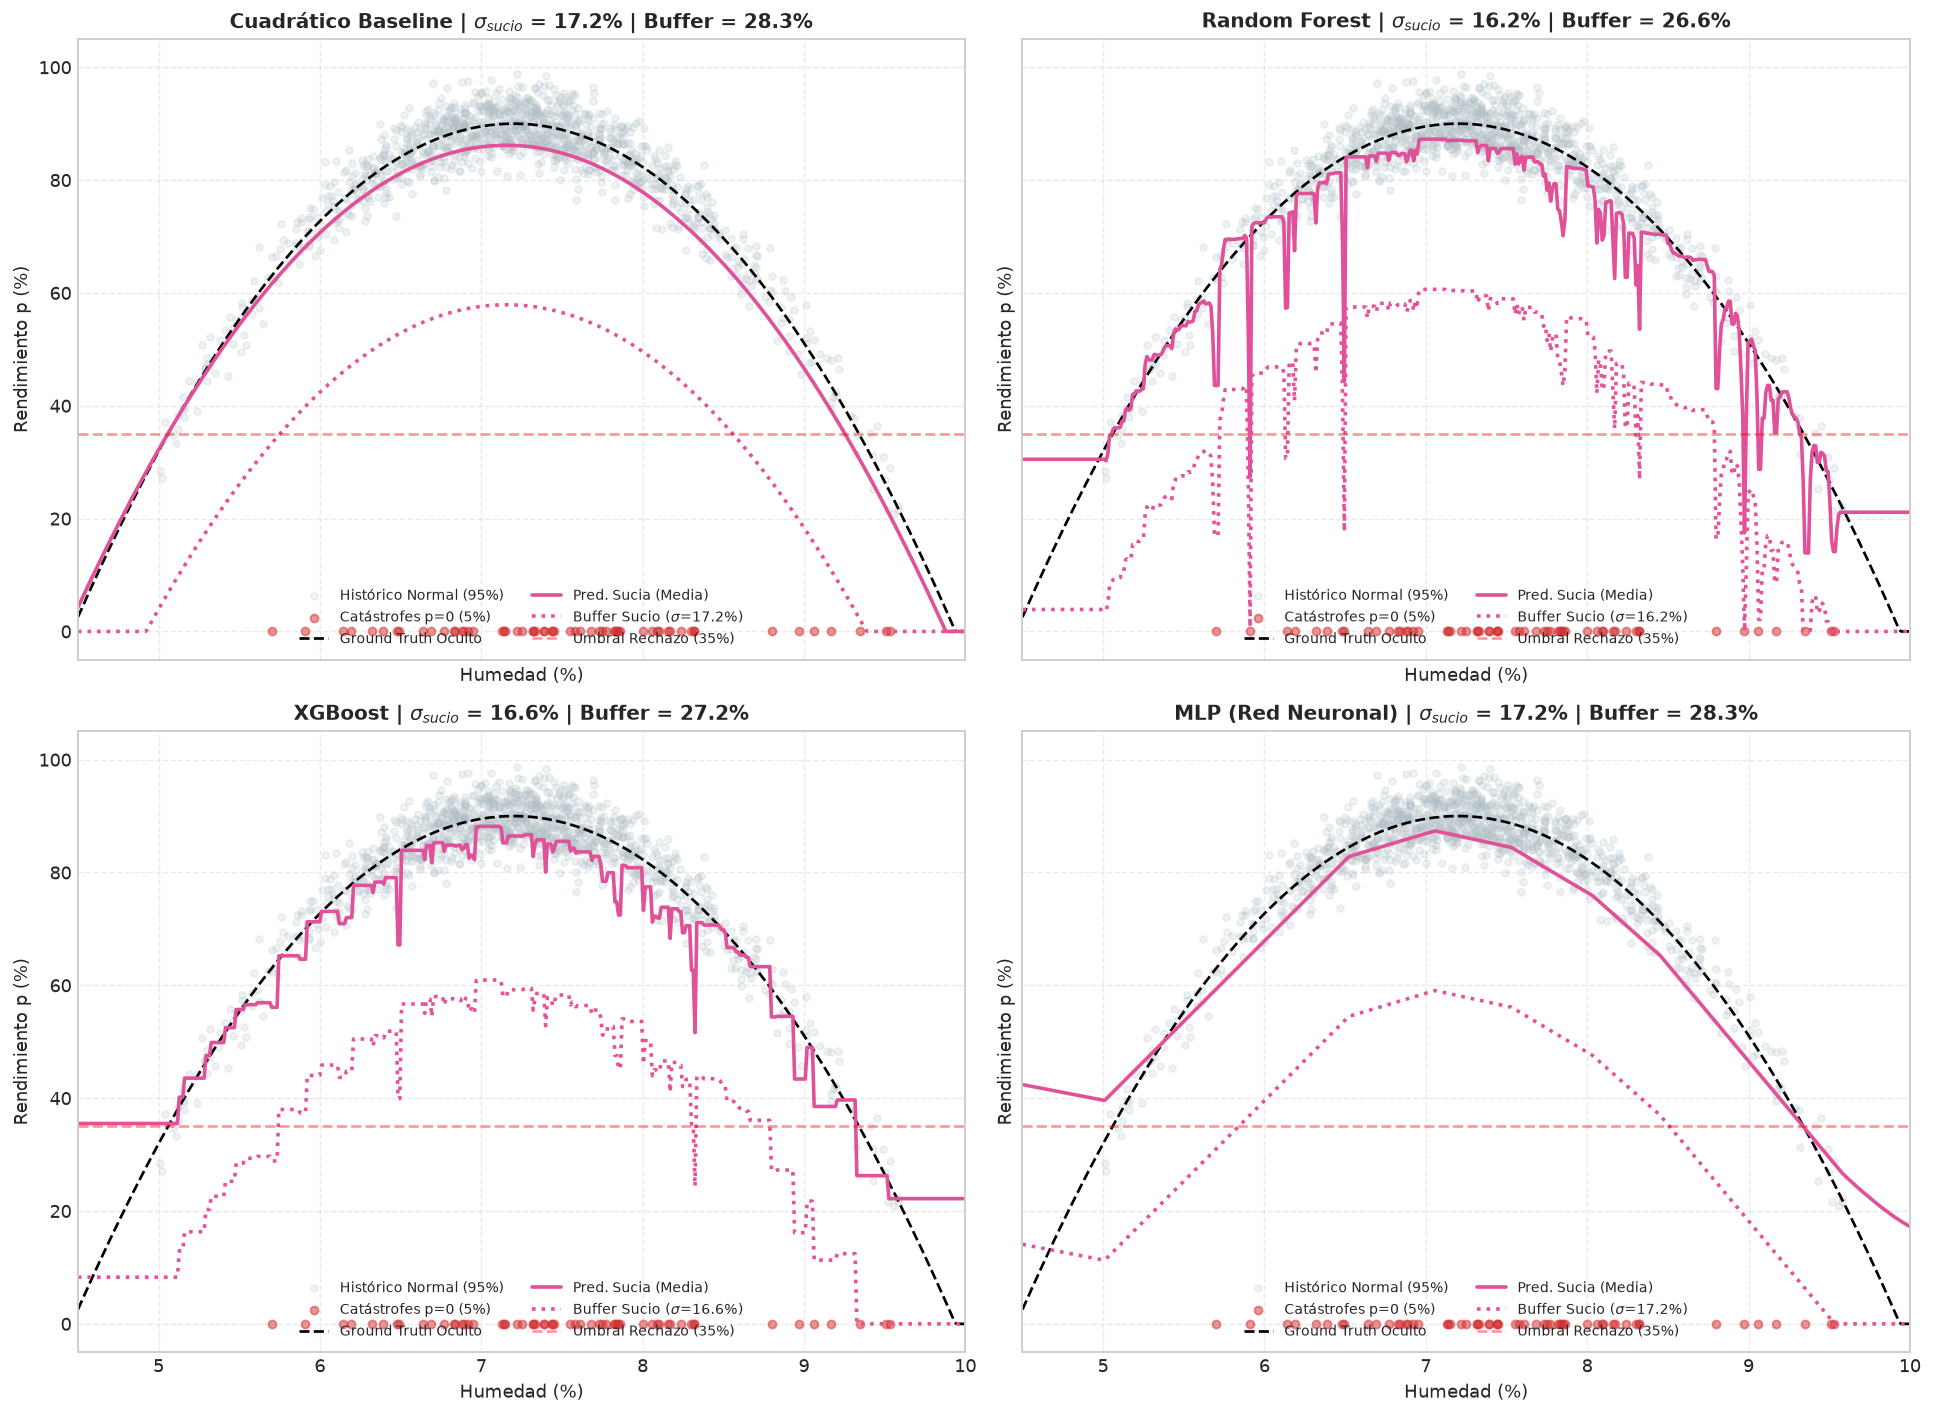

In [11]:
normales = df_hist_sucio[~df_hist_sucio['es_catastrofe']]
catastrofes = df_hist_sucio[df_hist_sucio['es_catastrofe']]

fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
axes = axes.flatten()

for idx, nombre in enumerate(modelos_sucios.keys()):
    ax = axes[idx]
    mod_s = modelos_sucios[nombre]
    sig_s = sigmas_sucios[nombre]
    pred_s = np.clip(mod_s.predict(df_grid), 0.0, 100.0)
    buf_s = np.clip(pred_s - (Z_VAL * sig_s), 0.0, 100.0)

    ax.scatter(normales['humedad'], normales['p_real'], color='#b0bec5', alpha=0.20, s=15, label='Histórico Normal (95%)')
    ax.scatter(catastrofes['humedad'], catastrofes['p_real'], color='#d32f2f', alpha=0.50, s=20, label='Catástrofes p=0 (5%)')
    ax.plot(h_grid, p_ground_truth, 'k--', linewidth=1.5, label='Ground Truth Oculto')
    ax.plot(h_grid, pred_s, color='#e15199', linewidth=2.0, label='Pred. Sucia (Media)')
    ax.plot(h_grid, buf_s, color='#e65199', linestyle=':', linewidth=2.0, label=f'Buffer Sucio ($\sigma$={sig_s:.1f}%)')
    ax.axhline(35, color='red', linestyle='--', alpha=0.4, label='Umbral Rechazo (35%)')

    ax.set_title(f'{nombre} | $\sigma_{{sucio}}$ = {sig_s:.1f}% | Buffer = {Z_VAL * sig_s:.1f}%', fontsize=11, fontweight='bold')
    ax.set_ylabel('Rendimiento p (%)')
    ax.set_xlabel('Humedad (%)')
    ax.set_ylim(-5, 105)
    ax.set_xlim(4.5, 10.0)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower center', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

## 5. Auditoría de Residuos y Detección de Anomalías (MLOps)

Para resolver este dilema no modificamos el algoritmo: aplicamos **criterio de dominio**.
Ajustamos un **modelo auditor cuadrático** y calculamos el residuo estudentizado:
$$e_i = p_{\text{real}, i} - \hat{p}_{\text{auditoría}}(h_i)$$

Como el ruido natural es gaussiano ($\sigma \approx 3.5\%$), un residuo $< -20.0\%$ (más de $5\sigma$) es inequívocamente una catástrofe exógena.
* **Máscara limpia:** $e_i > -20.0\%$.
* Las anomalías se envían a cuarentena (pólizas de seguro agropecuario) y **se excluyen del reentrenamiento del modelo físico**.

Lotes históricos analizados:  1300
Lotes clasificados catástrofe: 59 (4.5%)
Lotes en dataset limpio:      1241

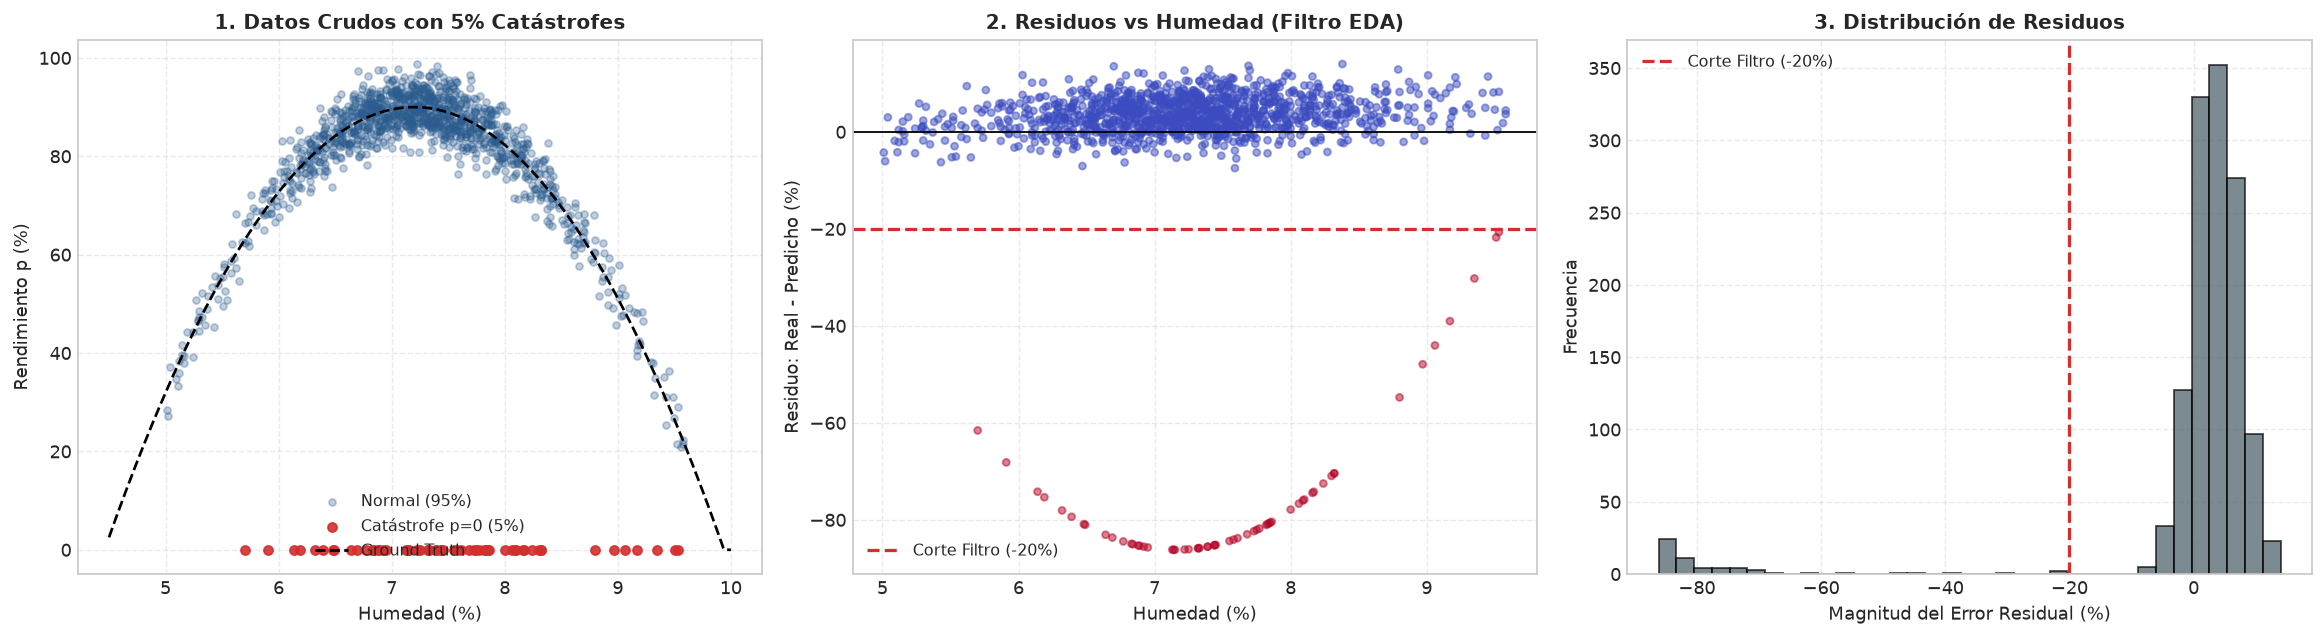

In [12]:
poly_auditor = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])
poly_auditor.fit(df_hist_sucio[['humedad']], df_hist_sucio['p_real'])

preds_auditoria = poly_auditor.predict(df_hist_sucio[['humedad']])
residuos_auditoria = df_hist_sucio['p_real'] - preds_auditoria

mascara_limpia = residuos_auditoria > -20.0
df_hist_limpio = df_hist_sucio[mascara_limpia].copy()
lotes_descartados = len(df_hist_sucio) - len(df_hist_limpio)
pct_descartados = (lotes_descartados / len(df_hist_sucio)) * 100.0

print(f"Lotes históricos analizados:  {len(df_hist_sucio)}")
print(f"Lotes clasificados catástrofe: {lotes_descartados} ({pct_descartados:.1f}%)")
print(f"Lotes en dataset limpio:      {len(df_hist_limpio)}")

# Diagnóstico en 3 paneles
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# 1. Datos crudos
ax1.scatter(normales['humedad'], normales['p_real'], color='#2b5c8f', alpha=0.3, s=15, label='Normal (95%)')
ax1.scatter(catastrofes['humedad'], catastrofes['p_real'], color='#d32f2f', alpha=0.9, s=25, label='Catástrofe p=0 (5%)')
ax1.plot(h_grid, p_ground_truth, 'k--', linewidth=1.5, label='Ground Truth')
ax1.set_title('1. Datos Crudos con 5% Catástrofes', fontsize=11, fontweight='bold')
ax1.set_xlabel('Humedad (%)')
ax1.set_ylabel('Rendimiento p (%)')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='lower center', fontsize=9)

# 2. Residuos vs Humedad
ax2.scatter(df_hist_sucio['humedad'], residuos_auditoria, c=mascara_limpia, cmap='coolwarm_r', alpha=0.5, s=15)
ax2.axhline(0, color='black', lw=1.0)
ax2.axhline(-20.0, color='#d32f2f', linestyle='--', lw=1.8, label='Corte Filtro (-20%)')
ax2.set_title('2. Residuos vs Humedad (Filtro EDA)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Humedad (%)')
ax2.set_ylabel('Residuo: Real - Predicho (%)')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='lower left', fontsize=9)

# 3. Histograma de Residuos
ax3.hist(residuos_auditoria, bins=35, color='#455a64', edgecolor='black', alpha=0.7)
ax3.axvline(-20.0, color='#d32f2f', linestyle='--', lw=1.8, label='Corte Filtro (-20%)')
ax3.set_title('3. Distribución de Residuos', fontsize=11, fontweight='bold')
ax3.set_xlabel('Magnitud del Error Residual (%)')
ax3.set_ylabel('Frecuencia')
ax3.grid(True, linestyle='--', alpha=0.4)
ax3.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

## 6. Resolución del Dilema Financiero bajo Cisnes Negros

Reentrenamos la suite sobre el dataset limpio (`df_hist_limpio`) y enfrentamos las 4 estrategias en el horizonte futuro contaminado (520 lotes a 2 años):
1. **Limpio con Buffer (Estrategia Óptima):** Modelo limpio con buffer saludable ($\sigma pprox 3.4\% \implies 	ext{Buffer} pprox 5.6\%$).
2. **Sucio Directo:** Modelo sucio sin buffer (baja sus predicciones por azar, amortiguando multas).
3. **Limpio Directo:** Modelo limpio sin buffer (vulnerable a penalizaciones de \$15/kg).
4. **Sucio con Buffer:** Modelo sucio con buffer colapsado al 28% (destrucción masiva de margen).

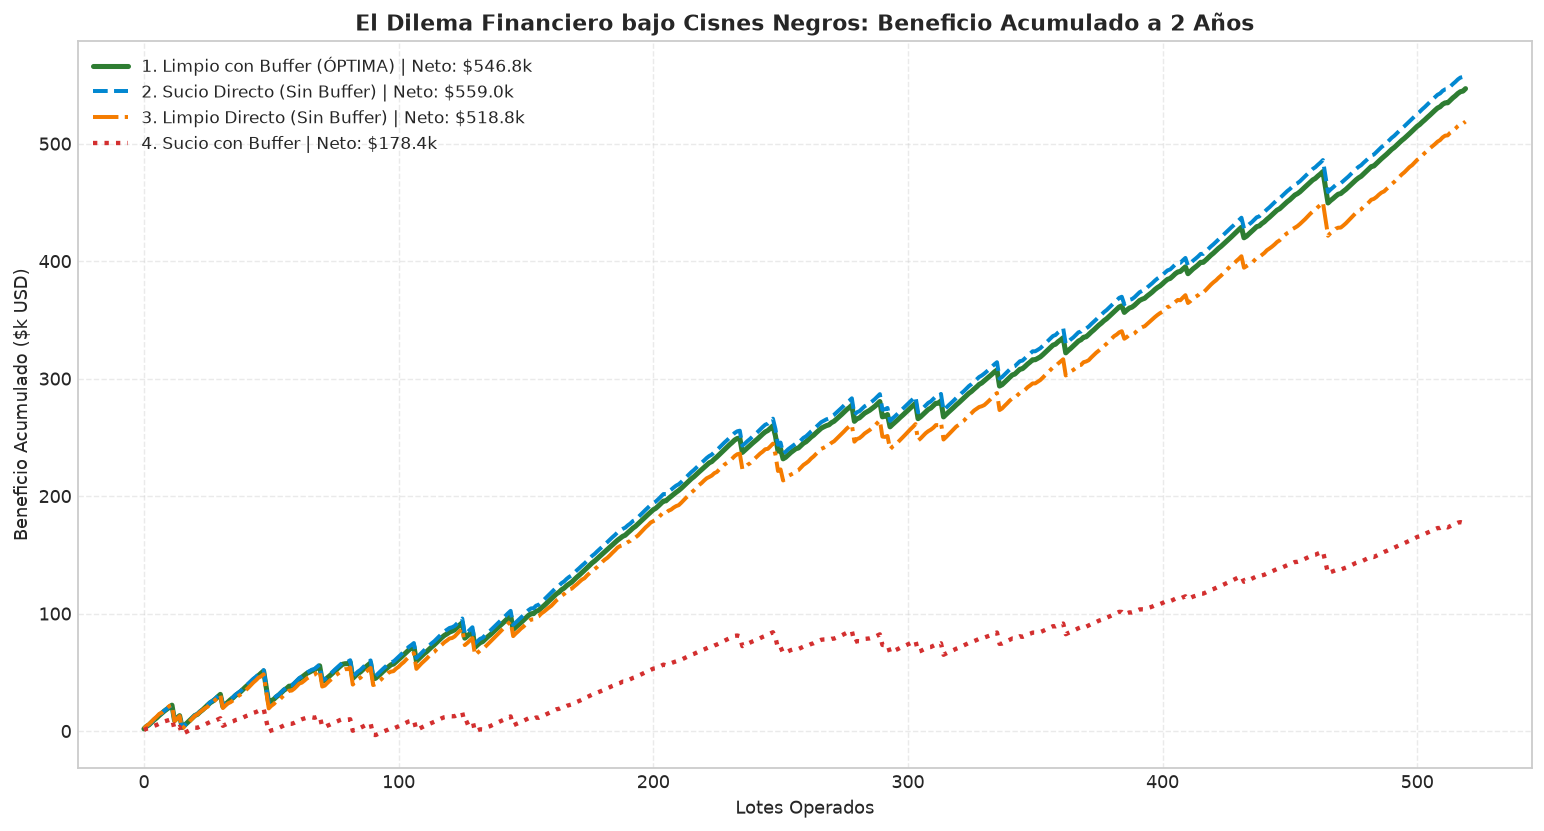

In [13]:
modelos_limpios = crear_suite_modelos()
sigmas_limpios = {}

for nombre, mod in modelos_limpios.items():
    mod.fit(df_hist_limpio[['humedad']], df_hist_limpio['p_real'])
    preds_l = mod.predict(df_hist_limpio[['humedad']])
    sigmas_limpios[nombre] = np.std(df_hist_limpio['p_real'] - preds_l, ddof=1)

mod_cuad_sucio = modelos_sucios["Cuadrático Baseline"]
mod_cuad_limpio = modelos_limpios["Cuadrático Baseline"]
sig_s = sigmas_sucios["Cuadrático Baseline"]
sig_l = sigmas_limpios["Cuadrático Baseline"]

res_dirty_dir = ejecutar_simulacion(df_futuro_catastrofe, mod_cuad_sucio, buffer_val=0.0, col_y="p_real", multa=15.0)
res_dirty_buf = ejecutar_simulacion(df_futuro_catastrofe, mod_cuad_sucio, buffer_val=Z_VAL * sig_s, col_y="p_real", multa=15.0)
res_clean_dir = ejecutar_simulacion(df_futuro_catastrofe, mod_cuad_limpio, buffer_val=0.0, col_y="p_real", multa=15.0)
res_clean_buf = ejecutar_simulacion(df_futuro_catastrofe, mod_cuad_limpio, buffer_val=Z_VAL * sig_l, col_y="p_real", multa=15.0)

# Gráfico de trayectorias acumuladas
plt.figure(figsize=(12, 6.5))
curvas_4 = {
    "1. Limpio con Buffer (ÓPTIMA)": (res_clean_buf["Curva_Acumulada"], "#2e7d32", "-", 2.8),
    "2. Sucio Directo (Sin Buffer)": (res_dirty_dir["Curva_Acumulada"], "#0288d1", "--", 2.2),
    "3. Limpio Directo (Sin Buffer)": (res_clean_dir["Curva_Acumulada"], "#f57c00", "-.", 2.2),
    "4. Sucio con Buffer": (res_dirty_buf["Curva_Acumulada"], "#d32f2f", ":", 2.4),
}

for etiqueta, (curva_data, color, estilo, grosor) in curvas_4.items():
    curva = np.array(curva_data) / 1000.0
    plt.plot(curva, label=f"{etiqueta} | Neto: ${curva[-1]:.1f}k", color=color, linestyle=estilo, linewidth=grosor)

plt.title("El Dilema Financiero bajo Cisnes Negros: Beneficio Acumulado a 2 Años", fontsize=12, fontweight="bold")
plt.xlabel("Lotes Operados")
plt.ylabel("Beneficio Acumulado ($k USD)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="upper left", fontsize=9.5)
plt.tight_layout()
plt.show()

In [14]:
# Simulación específica de XGBoost para responder a la Tabla del Capítulo
sig_xgb_l = sigmas_limpios['XGBoost']
sig_xgb_s = sigmas_sucios['XGBoost']

xgb_sucio_dir = ejecutar_simulacion(df_futuro_catastrofe, modelos_sucios['XGBoost'], buffer_val=0.0, col_y='p_real', multa=15.0)
xgb_limpio_buf = ejecutar_simulacion(df_futuro_catastrofe, modelos_limpios['XGBoost'], buffer_val=1.645 * sig_xgb_l, col_y='p_real', multa=15.0)

df_comp_xgb = pd.DataFrame([
    {
        "Métrica / Concepto": "Lotes Procesados",
        "Sucio sin Buffer": f"{xgb_sucio_dir['Lotes Procesados']}",
        "Limpio con Buffer": f"{xgb_limpio_buf['Lotes Procesados']}",
        "Diferencia (Δ)": f"{xgb_limpio_buf['Lotes Procesados'] - xgb_sucio_dir['Lotes Procesados']}"
    },
    {
        "Métrica / Concepto": "Lotes Multados (%)",
        "Sucio sin Buffer": f"{xgb_sucio_dir['Lotes Multados']} ({xgb_sucio_dir['Tasa Falla (%)']}%)",
        "Limpio con Buffer": f"{xgb_limpio_buf['Lotes Multados']} ({xgb_limpio_buf['Tasa Falla (%)']}%)",
        "Diferencia (Δ)": f"{xgb_limpio_buf['Lotes Multados'] - xgb_sucio_dir['Lotes Multados']} ({xgb_limpio_buf['Tasa Falla (%)'] - xgb_sucio_dir['Tasa Falla (%)']:.1f}%)"
    },
    {
        "Métrica / Concepto": "Volumen Alta Calidad (kg)",
        "Sucio sin Buffer": f"{xgb_sucio_dir['Kg Vendidos Alta']:,.1f}",
        "Limpio con Buffer": f"{xgb_limpio_buf['Kg Vendidos Alta']:,.1f}",
        "Diferencia (Δ)": f"{xgb_limpio_buf['Kg Vendidos Alta'] - xgb_sucio_dir['Kg Vendidos Alta']:,.1f}"
    },
    {
        "Métrica / Concepto": "Déficit Penalizado (kg)",
        "Sucio sin Buffer": f"{xgb_sucio_dir['Kg Multados']:,.1f}",
        "Limpio con Buffer": f"{xgb_limpio_buf['Kg Multados']:,.1f}",
        "Diferencia (Δ)": f"{xgb_limpio_buf['Kg Multados'] - xgb_sucio_dir['Kg Multados']:,.1f}"
    },
    {
        "Métrica / Concepto": "Ingresos por Ventas ($k)",
        "Sucio sin Buffer": f"${xgb_sucio_dir['Ingresos ($k)']:.1f}k",
        "Limpio con Buffer": f"${xgb_limpio_buf['Ingresos ($k)']:.1f}k",
        "Diferencia (Δ)": f"${xgb_limpio_buf['Ingresos ($k)'] - xgb_sucio_dir['Ingresos ($k)']:.1f}k"
    },
    {
        "Métrica / Concepto": "Multas Pagadas ($k)",
        "Sucio sin Buffer": f"${xgb_sucio_dir['Multas ($k)']:.1f}k",
        "Limpio con Buffer": f"${xgb_limpio_buf['Multas ($k)']:.1f}k",
        "Diferencia (Δ)": f"${xgb_limpio_buf['Multas ($k)'] - xgb_sucio_dir['Multas ($k)']:.1f}k"
    },
    {
        "Métrica / Concepto": "Beneficio Neto Final ($k)",
        "Sucio sin Buffer": f"${xgb_sucio_dir['Beneficio Neto ($k)']:.1f}k",
        "Limpio con Buffer": f"${xgb_limpio_buf['Beneficio Neto ($k)']:.1f}k",
        "Diferencia (Δ)": f"+${xgb_limpio_buf['Beneficio Neto ($k)'] - xgb_sucio_dir['Beneficio Neto ($k)']:.1f}k"
    }
]).set_index("Métrica / Concepto")

print("Tabla 2: Comparativa Económica y Operativa: XGBoost Sucio sin Buffer vs Limpio con Buffer:")
print(df_comp_xgb.to_string())

Tabla 2: Comparativa Económica y Operativa: XGBoost Sucio sin Buffer vs Limpio con Buffer:
                          Sucio sin Buffer Limpio con Buffer Diferencia (Δ)
Métrica / Concepto                                                         
Lotes Procesados                       515               512             -3
Lotes Multados (%)             109 (21.2%)        52 (10.2%)   -57 (-11.0%)
Volumen Alta Calidad (kg)        383,074.4         373,659.4       -9,415.0
Déficit Penalizado (kg)           22,644.4          19,912.5       -2,731.9
Ingresos por Ventas ($k)          $2073.7k          $2034.3k        $-39.4k
Multas Pagadas ($k)                $339.7k           $298.7k        $-41.0k
Beneficio Neto Final ($k)          $549.5k           $558.0k         +$8.5k

## 7. Optimización de la Regla de Rechazo en Báscula ($th^*$)

Cuando llega el camión, la planta predice $\hat{p}$. Si $\hat{p} < th$, el cargamento se devuelve al productor, ahorrando el costo de compra (\$2,000) y de beneficio (\$300).
* **Punto de equilibrio físico:** $38 \cdot p^* + 1200 = 2300 \implies p^* = 28.95\%$.
* **El dilema de la incertidumbre:** Debido al error del modelo ($\sigma \approx 3.5\%$) y a las multas punitivas de \$15/kg, procesar lotes con calidad esperada entre $30\%$ y $65\%$ tiene un valor esperado negativo.
* **El umbral óptimo operativo:** Se sitúa en $th^* = 69\%$, maximizando el beneficio neto acumulado a **\$567.8k**.

Umbral óptimo operativo: th* = 69% (Beneficio máximo = $567.8k)

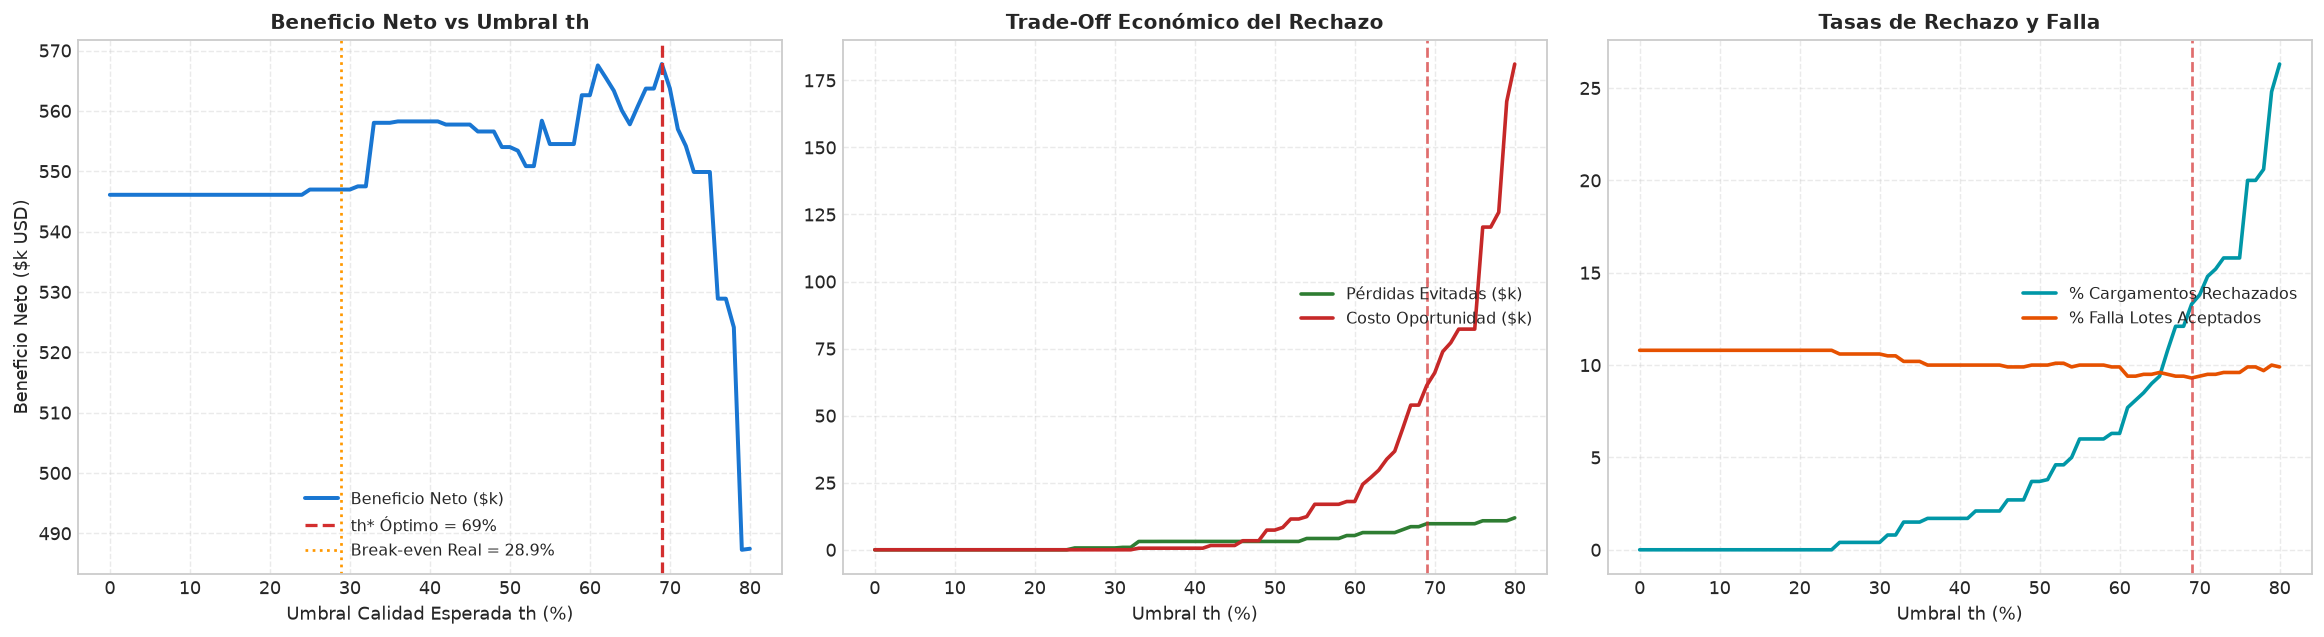

In [15]:
reales = df_futuro_catastrofe['p_real'].values
preds_xgb = np.clip(modelos_limpios['XGBoost'].predict(df_futuro_catastrofe[['humedad']]), 0.0, 100.0)
costo_base = 2300.0
p_be = 28.95

umbrales_sweep = np.arange(0.0, 81.0, 1.0)
registros_th = []

for th in umbrales_sweep:
    proc, rech, mult_lotes = 0, 0, 0
    rech_corr, falsos_rech = 0, 0
    costo_op, perd_evit, multas_tot, beneficio_tot = 0.0, 0.0, 0.0, 0.0

    for real, pred in zip(reales, preds_xgb):
        kg_alta = (real / 100.0) * 1000.0
        kg_baja = ((100.0 - real) / 100.0) * 1000.0
        margen_pot = (kg_alta * 5.00 + kg_baja * 1.20) - costo_base

        if pred < th:
            rech += 1
            if margen_pot > 0:
                falsos_rech += 1
                costo_op += margen_pot
            else:
                rech_corr += 1
                perd_evit += abs(margen_pot)
            continue

        proc += 1
        p_comp = max(0.0, pred - (1.645 * sig_xgb_l))
        kg_comp = (p_comp / 100.0) * 1000.0

        if kg_alta >= kg_comp:
            kg_v_alta = kg_comp
            kg_v_baja = kg_baja + (kg_alta - kg_comp)
            m_lote = 0.0
        else:
            kg_v_alta = kg_alta
            kg_v_baja = kg_baja
            m_lote = (kg_comp - kg_alta) * 15.00
            multas_tot += m_lote
            mult_lotes += 1

        beneficio_tot += (kg_v_alta * 5.00 + kg_v_baja * 1.20) - (costo_base + m_lote)

    tasa_rech = (rech / len(reales)) * 100.0
    tasa_falla = (mult_lotes / proc * 100.0) if proc > 0 else 0.0

    registros_th.append({
        'th': th,
        'Beneficio ($k)': round(beneficio_tot / 1000.0, 2),
        'Pérdidas Evitadas ($k)': round(perd_evit / 1000.0, 2),
        'Costo Oportunidad ($k)': round(costo_op / 1000.0, 2),
        'Multas ($k)': round(multas_tot / 1000.0, 2),
        'Rechazo (%)': round(tasa_rech, 1),
        'Falla Lotes (%)': round(tasa_falla, 1),
    })

df_sweep = pd.DataFrame(registros_th)
th_opt = df_sweep.loc[df_sweep['Beneficio ($k)'].idxmax(), 'th']

# Gráficos de Trade-Off
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# 1. Beneficio vs Umbral
ax1.plot(df_sweep['th'], df_sweep['Beneficio ($k)'], color='#1976d2', lw=2.2, label='Beneficio Neto ($k)')
ax1.axvline(th_opt, color='#d32f2f', linestyle='--', lw=1.8, label=f'th* Óptimo = {th_opt:.0f}%')
ax1.axvline(p_be, color='#ff9800', linestyle=':', lw=1.5, label=f'Break-even Real = {p_be:.1f}%')
ax1.set_title('Beneficio Neto vs Umbral th', fontsize=11, fontweight='bold')
ax1.set_xlabel('Umbral Calidad Esperada th (%)')
ax1.set_ylabel('Beneficio Neto ($k USD)')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='lower center', fontsize=9)

# 2. Pérdidas Evitadas vs Costo Oportunidad
ax2.plot(df_sweep['th'], df_sweep['Pérdidas Evitadas ($k)'], color='#2e7d32', lw=2.0, label='Pérdidas Evitadas ($k)')
ax2.plot(df_sweep['th'], df_sweep['Costo Oportunidad ($k)'], color='#c62828', lw=2.0, label='Costo Oportunidad ($k)')
ax2.axvline(th_opt, color='#d32f2f', linestyle='--', lw=1.5, alpha=0.7)
ax2.set_title('Trade-Off Económico del Rechazo', fontsize=11, fontweight='bold')
ax2.set_xlabel('Umbral th (%)')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='center right', fontsize=9)

# 3. Tasas Operativas
ax3.plot(df_sweep['th'], df_sweep['Rechazo (%)'], color='#0097a7', lw=2.0, label='% Cargamentos Rechazados')
ax3.plot(df_sweep['th'], df_sweep['Falla Lotes (%)'], color='#e65100', lw=2.0, label='% Falla Lotes Aceptados')
ax3.axvline(th_opt, color='#d32f2f', linestyle='--', lw=1.5, alpha=0.7)
ax3.set_title('Tasas de Rechazo y Falla', fontsize=11, fontweight='bold')
ax3.set_xlabel('Umbral th (%)')
ax3.grid(True, linestyle='--', alpha=0.4)
ax3.legend(loc='center right', fontsize=9)

plt.tight_layout()
plt.show()

print(f"Umbral óptimo operativo: th* = {th_opt:.0f}% (Beneficio máximo = ${df_sweep['Beneficio ($k)'].max():.1f}k)")

### Extracción de Parámetros Físicos Ocultos vs Ground Truth
Verificamos analíticamente si el modelo cuadrático limpio recupera las constantes agronómicas reales ($P_{\text{MAX}} = 90\%$, $H_{\text{OPT}} = 7.2\%$, $K = 12.0$).

In [16]:
def extraer_parametros_parabola(pipeline_modelo):
    poly = pipeline_modelo.named_steps['poly']
    lin = pipeline_modelo.named_steps['linear']
    powers = poly.powers_.flatten()

    a, b, c = 0.0, 0.0, float(lin.intercept_)
    for p, coef in zip(powers, lin.coef_):
        if p == 2:
            a = float(coef)
        elif p == 1:
            b = float(coef)
        elif p == 0:
            c += float(coef)

    k = -a
    h_opt = -b / (2.0 * a) if a != 0 else 0.0
    p_max = c - (b ** 2) / (4.0 * a) if a != 0 else 0.0

    return {'a': a, 'b': b, 'c': c, 'k': k, 'h_opt': h_opt, 'p_max': p_max}

params_real = {'a': -12.0, 'b': 172.8, 'c': -532.08, 'k': 12.0, 'h_opt': 7.20, 'p_max': 90.0}
params_limpio = extraer_parametros_parabola(modelos_limpios['Cuadrático Baseline'])
params_sucio = extraer_parametros_parabola(modelos_sucios['Cuadrático Baseline'])

df_params = pd.DataFrame({
    'Parámetro Agronómico': ['Humedad Óptima (h_opt %)', 'Rendimiento Techo (P_max %)', 'Sensibilidad Curvatura (K)', 'Coeficiente Cuadrático (a)'],
    'Ground Truth Teórico': [f"{params_real['h_opt']:.2f}%", f"{params_real['p_max']:.2f}%", f"{params_real['k']:.2f}", f"{params_real['a']:.2f}"],
    'Modelo Limpio (Post-EDA)': [f"{params_limpio['h_opt']:.2f}%", f"{params_limpio['p_max']:.2f}%", f"{params_limpio['k']:.2f}", f"{params_limpio['a']:.2f}"],
    'Modelo Sucio (Con 5% Catástrofes)': [f"{params_sucio['h_opt']:.2f}%", f"{params_sucio['p_max']:.2f}%", f"{params_sucio['k']:.2f}", f"{params_sucio['a']:.2f}"]
})

print("Recuperación de Parámetros Físicos del Proceso:")
print(df_params.to_string(index=False))

Recuperación de Parámetros Físicos del Proceso:
       Parámetro Agronómico Ground Truth Teórico Modelo Limpio (Post-EDA) Modelo Sucio (Con 5% Catástrofes)
   Humedad Óptima (h_opt %)                7.20%                    7.20%                             7.16%
Rendimiento Techo (P_max %)               90.00%                   89.91%                            86.17%
 Sensibilidad Curvatura (K)                12.00                    11.93                             11.62
 Coeficiente Cuadrático (a)               -12.00                   -11.93                            -11.62

## 8. Conclusiones y Filosofía Antifrágil

1. **La Asimetría de Pérdidas Gobierna el Problema:** Reducir el RMSE no es el fin último de la ciencia de datos. En entornos con funciones de costo asimétricas (multas punitivas vs ingresos limitados), la predicción puntual ($\hat{y}$) es insuficiente; la viabilidad del negocio depende de incorporar un **buffer de seguridad estocástico** ($z \cdot \sigma$).
2. **Los Cisnes Negros no se Modelan con Tolerancia Algorítmica:** Forzar a un modelo de ML a aprender anomalías exógenas infla artificialmente la varianza residual y paraliza las ventas comerciales («los seguros caen al piso»). Las catástrofes se aíslan mediante **auditoría de residuos** y se gestionan con herramientas financieras externas (seguros o contratos de contingencia).
3. **El Nuevo Rol del Científico de Datos:** Con el auge de los agentes de código (Gemini, Antigravity, LLMs), la programación instrumental y la limpieza de código se resuelven en minutos. La verdadera ventaja competitiva está en **entender la física del dominio, detectar la convexidad del riesgo y diseñar mecanismos de decisión robustos**.